<a href="https://colab.research.google.com/github/Nidhiisinhaaa/NLP-EXPERIMENTS-SEM-7/blob/main/EXP_10_LLM_LangChain_LangGraph_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Exploring and Implementing Large Language Model using LangChain and LangGraph

**Aim:** To explore Large Language Models and implement LLM-based applications using LangChain (chains) and LangGraph (graph workflows).

**Before running:** Get a free API key from https://console.groq.com/keys

## Step 1: Install libraries

In [ ]:
!pip install -q langchain langchain-groq langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.2 MB/s eta 0:00:00


## Step 2: Set Groq API key

In [ ]:
import os
from getpass import getpass

# Option 1: Colab Secrets (key icon on left sidebar -> add GROQ_API_KEY)
# Option 2: type the key when asked
try:
    from google.colab import userdata
    os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
    print("API key loaded from Colab Secrets")
except Exception:
    os.environ["GROQ_API_KEY"] = getpass("Enter Groq API key: ")

Enter Groq API key: ··········


## Step 3: Load the LLM using LangChain

In [ ]:
from groq import Groq
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# Fetch the models currently available on your Groq account
available = [m.id for m in Groq().models.list().data]
skip = ["whisper", "tts", "guard", "playai", "orpheus", "compound"]
chat_models = [m for m in available if not any(x in m for x in skip)]
print("Available chat models:", chat_models)

# Pick the first preferred model that exists, else any chat model
preferred = ["llama-3.3-70b-versatile", "openai/gpt-oss-20b", "openai/gpt-oss-120b",
             "meta-llama/llama-4-scout-17b-16e-instruct", "qwen/qwen3-32b"]
MODEL = next((m for m in preferred if m in chat_models), chat_models[0])
print("Using model:", MODEL)

llm = ChatGroq(model=MODEL, temperature=0.7)

response = llm.invoke("What is a Large Language Model? Answer in 2 lines.")
print(response.content)

Available chat models: ['allam-2-7b', 'openai/gpt-oss-120b', 'openai/gpt-oss-20b', 'qwen/qwen3.8-27b']
Using model: openai/gpt-oss-20b
A large language model is a deep neural network trained on vast text data to predict and generate human‑like language.  
It learns statistical patterns and semantic relationships, enabling it to answer questions, translate, summarize, and more.


## Step 4: Simple Chain (Prompt -> LLM -> Output Parser)

In [ ]:
prompt = ChatPromptTemplate.from_template("Explain {topic} to a beginner in 3 points.")
chain = prompt | llm | StrOutputParser()

print(chain.invoke({"topic": "Transformer architecture"}))

**Transformer in 3 easy‑to‑understand points**

1. **Self‑Attention = “look‑at‑all‑words‑simultaneously”**  
   - Every word in a sentence “sees” every other word at the same time.  
   - The model learns how much each word should influence the others, creating a weighted summary of the whole sentence.  
   - This replaces older models that processed words one after another (e.g., RNNs).

2. **Layered Encoder‑Decoder Blocks**  
   - The *encoder* stacks several self‑attention layers to turn the input words into a rich, context‑aware representation.  
   - The *decoder* does the same, but also attends to the encoder’s output, so it can generate new words (e.g., translation, summarization).  
   - Each block has two main parts: **self‑attention** (or cross‑attention in the decoder) and a small feed‑forward neural network, with shortcuts (“residual connections”) that help gradients flow.

3. **Position Matters – Positional Encoding**  
   - Since self‑attention treats all words equally, t

## Step 5: Sequential Chain (output of one chain -> input of next)

In [ ]:
title_prompt = ChatPromptTemplate.from_template(
    "Give one catchy blog title about {topic}. Only give the title.")
intro_prompt = ChatPromptTemplate.from_template(
    "Write a 4-line introduction for a blog titled: {title}")

title_chain = title_prompt | llm | StrOutputParser()
seq_chain = {"title": title_chain} | intro_prompt | llm | StrOutputParser()

topic = "AI in education"
print("Title:", title_chain.invoke({"topic": topic}))
print("\nIntroduction:\n", seq_chain.invoke({"topic": topic}))

Title: From Chalkboards to Chatbots: AI's Classroom Revolution

Introduction:
 From dusty chalkboards to sleek digital screens,  
We’ve taught the world with ink and quiet screams.  
Now AI whispers in our students’ ears,  
Rewriting futures, one chatbot at a time.


## Step 6: LangGraph Workflow (State, Nodes, Conditional Edge)

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# State: shared data between nodes
class State(TypedDict):
    question: str
    category: str
    answer: str

# Node 1: classify the question
def classify(state: State):
    res = llm.invoke(
        "Classify the question as 'tech' or 'general'. Reply with one word only.\n"
        f"Question: {state['question']}").content.lower()
    return {"category": "tech" if "tech" in res else "general"}

# Node 2: technical answer
def tech_node(state: State):
    ans = llm.invoke(f"You are a technical expert. Answer briefly: {state['question']}")
    return {"answer": ans.content}

# Node 3: general answer
def general_node(state: State):
    ans = llm.invoke(f"You are a friendly assistant. Answer briefly: {state['question']}")
    return {"answer": ans.content}

# Router for conditional edge
def route(state: State):
    return state["category"]

# Build the graph
graph = StateGraph(State)
graph.add_node("classify", classify)
graph.add_node("tech", tech_node)
graph.add_node("general", general_node)

graph.add_edge(START, "classify")
graph.add_conditional_edges("classify", route, {"tech": "tech", "general": "general"})
graph.add_edge("tech", END)
graph.add_edge("general", END)

app = graph.compile()
print("Graph compiled successfully")

Graph compiled successfully


## Step 7: Visualize the graph

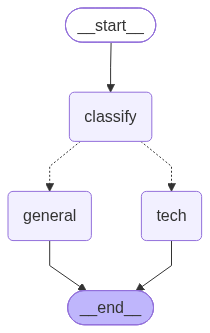

In [ ]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Image render failed, showing Mermaid text instead:\n")
    print(app.get_graph().draw_mermaid())

## Step 8: Test the LangGraph workflow

In [ ]:
questions = [
    "What is self-attention in transformers?",
    "Suggest a good weekend hobby"
]

for q in questions:
    result = app.invoke({"question": q})
    print("Q:", q)
    print("Category:", result["category"])
    print("A:", result["answer"])
    print("-" * 60)

Q: What is self-attention in transformers?
Category: tech
A: Self‑attention is a core transformer operation that lets each token in a sequence “attend” to every other token.  
For each token a **query** vector is compared (dot‑product) with **key** vectors of all tokens; the resulting scores are softmax‑normalized to give attention weights.  
These weights re‑weight the corresponding **value** vectors and sum them, producing a context‑aware representation for that token.  
Thus, self‑attention captures long‑range dependencies and contextual relationships within the sequence.
------------------------------------------------------------
Q: Suggest a good weekend hobby
Category: general
A: How about trying a creative hobby like painting or sketching? It’s relaxing, lets you explore your imagination, and you can see tangible progress over the weekend.
------------------------------------------------------------


In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import time

GR_MAJOR = int(gr.__version__.split(".")[0])

# ---------- Helpers ----------
def to_text(content):
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        return " ".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in content)
    if isinstance(content, dict):
        return content.get("text", "")
    return str(content)

def build_context(history, max_turns=4):
    lines = []
    for m in history[-max_turns * 2:]:
        role = "User" if m.get("role") == "user" else "Assistant"
        text = to_text(m.get("content", ""))
        if role == "Assistant" and text.startswith("**["):
            text = text.split("\n\n", 1)[-1]   # remove the route tag
        lines.append(f"{role}: {text}")
    return "\n".join(lines)

def graph_html(active=None, category=None):
    """Draws the LangGraph flow and highlights the path taken."""
    def node(name, label, icon):
        on = active and (name in ("start", "classify", "end") or name == category)
        running = active == "running" and name in ("start", "classify")
        cls = "node on" if on and active != "running" else ("node run" if running else "node")
        return f'<div class="{cls}"><span>{icon}</span>{label}</div>'
    status = {None: "Waiting for a question…",
              "running": "⏳ Classifying the question…",
              "done": f"✅ Routed to <b>{'Tech Expert' if category=='tech' else 'General Assistant'}</b> node"}[active]
    return f"""
    <div class="graph">
      <div class="gtitle">LangGraph Live Trace</div>
      {node('start','START','▶️')}
      <div class="arrow">↓</div>
      {node('classify','classify','🔍')}
      <div class="arrow">↙ conditional edge ↘</div>
      <div class="branch">{node('tech','Tech Expert','🛠️')}{node('general','General','💬')}</div>
      <div class="arrow">↓</div>
      {node('end','END','🏁')}
      <div class="status">{status}</div>
    </div>"""

# ---------- Chat logic ----------
def respond(message, history):
    history = list(history or [])
    if not message or not message.strip():
        yield "", history, graph_html()
        return

    context = build_context(history)
    question = message if not context else (
        f"Previous conversation:\n{context}\n\nCurrent question: {message}")

    history.append({"role": "user", "content": message})
    history.append({"role": "assistant", "content": "⏳ Thinking…"})
    yield "", history, graph_html("running")

    try:
        result = app.invoke({"question": question})
        cat = result["category"]
        tag = "🛠️ Tech Expert" if cat == "tech" else "💬 General Assistant"
        reply = f"**[{tag}]**\n\n{result['answer']}"
    except Exception as e:
        cat, reply = None, f"⚠️ Error: {e}"

    shown = ""
    for word in reply.split(" "):
        shown += word + " "
        history[-1] = {"role": "assistant", "content": shown}
        time.sleep(0.015)
        yield "", history, graph_html("done" if cat else None, cat)

def clear_chat():
    return [], graph_html()

# ---------- Styling ----------
CSS = """
.gradio-container {max-width: 1200px !important; margin: auto;}
#header {background: linear-gradient(135deg,#4f46e5 0%,#7c3aed 55%,#db2777 100%);
         border-radius: 18px; padding: 22px 28px; color: white; margin-bottom: 6px;}
#header h1 {margin: 0; font-size: 28px; color: white;}
#header p {margin: 6px 0 0; opacity: .9; color: white;}
.pill {display:inline-block; background: rgba(255,255,255,.2); padding: 3px 12px;
       border-radius: 999px; font-size: 13px; margin: 10px 6px 0 0; color: white;}
#chatbot {border-radius: 16px !important;}
#msg textarea {font-size: 15px !important;}
.graph {border:1px solid #e5e7eb; border-radius:16px; padding:16px; text-align:center;
        background: var(--background-fill-secondary);}
.gtitle {font-weight:700; margin-bottom:12px; font-size:15px;}
.node {display:inline-block; min-width:110px; padding:8px 12px; margin:2px 4px; border-radius:10px;
       border:2px solid #d1d5db; background: var(--background-fill-primary);
       font-weight:600; font-size:14px; transition: all .3s;}
.node span {margin-right:6px;}
.node.on {border-color:#7c3aed; background:#7c3aed; color:white; box-shadow:0 0 14px #7c3aed88;}
.node.run {border-color:#f59e0b; background:#fef3c7; color:#92400e;}
.arrow {color:#9ca3af; font-size:13px; margin:4px 0;}
.branch {display:flex; justify-content:center; gap:4px;}
.status {margin-top:14px; font-size:14px;}
.info {border:1px solid #e5e7eb; border-radius:16px; padding:14px 16px; margin-top:12px;
       font-size:13.5px; line-height:1.6; background: var(--background-fill-secondary);}
footer {display:none !important;}
"""

THEME = gr.themes.Soft(primary_hue="violet", secondary_hue="pink",
                       font=[gr.themes.GoogleFont("Poppins"), "sans-serif"])

blocks_kwargs = {"title": "LLM Chatbot · LangChain + LangGraph"}
if GR_MAJOR < 6:
    blocks_kwargs.update(theme=THEME, css=CSS)

chatbot_kwargs = dict(elem_id="chatbot", height=520, show_label=False,
                      placeholder="<h3>👋 Hi! Ask me anything.</h3>Tech questions go to the Tech Expert node, others to the General Assistant.")
if GR_MAJOR < 6:
    chatbot_kwargs["type"] = "messages"

with gr.Blocks(**blocks_kwargs) as demo:
    gr.HTML(f"""
    <div id="header">
      <h1> LLM Chatbot using LangChain & LangGraph</h1>
      <p>Every message passes through a LangGraph workflow that classifies it and routes it to the right expert node.</p>
      <span class="pill">🧠 Model: {MODEL}</span>
      <span class="pill">⚡ Powered by Groq</span>
      <span class="pill">🔗 LangChain + LangGraph</span>
    </div>""")

    with gr.Row():
        with gr.Column(scale=7):
            chatbot = gr.Chatbot(**chatbot_kwargs)
            with gr.Row():
                msg = gr.Textbox(elem_id="msg", placeholder="Type your message and press Enter…",
                                 show_label=False, scale=8, autofocus=True)
                send = gr.Button("Send ➤", variant="primary", scale=1)
            with gr.Row():
                clear = gr.Button("🗑️ New Chat", variant="secondary", size="sm")
            gr.Examples(examples=["What is self-attention in transformers?",
                                  "Explain LangChain in simple words",
                                  "Give an example of it",
                                  "Suggest a good weekend hobby"],
                        inputs=msg, label="Try these")

        with gr.Column(scale=4):
            trace = gr.HTML(graph_html())
            gr.HTML("""
            <div class="info">
              <b>How it works</b><br>
              1️⃣ Your message enters the graph at <b>START</b><br>
              2️⃣ <b>classify</b> node asks the LLM: tech or general?<br>
              3️⃣ A <b>conditional edge</b> picks the next node<br>
              4️⃣ The chosen node generates the answer<br>
              5️⃣ Last few messages are sent as context, so the bot remembers the chat
            </div>""")

    msg.submit(respond, [msg, chatbot], [msg, chatbot, trace])
    send.click(respond, [msg, chatbot], [msg, chatbot, trace])
    clear.click(clear_chat, None, [chatbot, trace])

launch_kwargs = dict(share=True, debug=False)
if GR_MAJOR >= 6:
    launch_kwargs.update(theme=THEME, css=CSS)
demo.launch(**launch_kwargs)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bfa7f86d1150921349.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


RAG

In [ ]:
!pip install -q gradio pypdf langchain-text-splitters langchain-huggingface sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.5/395.5 kB 6.9 MB/s eta 0:00:00


In [ ]:
from pypdf import PdfReader
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings

# 1. Embedding model: converts text into vectors (runs free inside Colab)
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# 2. Text splitter: breaks long text into small overlapping chunks
splitter = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=150)

# Knowledge base (currently loaded document)
KB = {"store": None, "name": None, "summary": "", "pages": 0, "chunks": 0}

def load_file(path):
    """Read a PDF or TXT file and return one Document per page."""
    if path.lower().endswith(".pdf"):
        reader = PdfReader(path)
        docs = [Document(page_content=p.extract_text() or "", metadata={"page": i + 1})
                for i, p in enumerate(reader.pages)]
    else:
        with open(path, encoding="utf-8", errors="ignore") as f:
            docs = [Document(page_content=f.read(), metadata={"page": 1})]
    return [d for d in docs if d.page_content.strip()]

def build_knowledge_base(docs, name):
    """Chunk -> Embed -> Store in vector store, then summarise the document."""
    if not docs:
        raise ValueError("No readable text found (scanned PDFs are not supported).")
    chunks = splitter.split_documents(docs)
    store = InMemoryVectorStore(embeddings)
    store.add_documents(chunks)
    full_text = " ".join(d.page_content for d in docs)
    summary = llm.invoke("In 2 short lines, what is this document about?\n\n" + full_text[:3000]).content
    KB.update(store=store, name=name, summary=summary.strip(),
              pages=len(docs), chunks=len(chunks))
    return KB

def clear_knowledge_base():
    KB.update(store=None, name=None, summary="", pages=0, chunks=0)

# Sample notes so the demo works even without a PDF
SAMPLE_NOTES = """Unit 3: Large Language Models (Class Notes)

A Large Language Model (LLM) is a deep learning model trained on a very large text corpus to understand and generate natural language. LLMs are based on the Transformer architecture introduced in 2017 in the paper "Attention Is All You Need". GPT-2 has 124 million parameters, while modern LLMs have billions of parameters.

Self-attention allows each token to look at every other token in the sequence and decide how important it is. Multi-head attention runs several attention operations in parallel so that the model can learn different kinds of relationships.

Tokenization splits text into tokens. Each token is converted into an embedding vector. Positional encoding is added because transformers do not understand word order by themselves.

Temperature controls randomness during generation. A low temperature such as 0.2 gives focused and predictable answers, while a high temperature such as 1.2 gives creative but less reliable answers.

LangChain is a framework for building LLM applications. Its main components are models, prompt templates, output parsers, chains, retrievers and memory. LangGraph is built on top of LangChain and is used to create stateful workflows made of nodes and edges. Conditional edges allow the graph to choose the next step, which is the basis of AI agents.

Retrieval Augmented Generation (RAG) reduces hallucination by retrieving relevant chunks from a document and giving them to the LLM as context. The steps of RAG are: load the document, split it into chunks, create embeddings, store them in a vector database, retrieve the most similar chunks for a question, and generate the answer using those chunks.

Limitations of LLMs include hallucination, bias from training data, high computational cost and a fixed knowledge cutoff date.

Practical exam: The LLM practical carries 25 marks. 10 marks are for the program, 10 marks for the output and 5 marks for the viva."""

def load_sample():
    return build_knowledge_base([Document(page_content=SAMPLE_NOTES, metadata={"page": 1})],
                                "Sample LLM Notes")

print("RAG setup ready ✅")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

RAG setup ready ✅


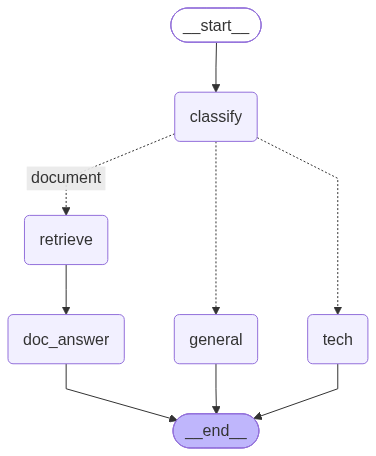


Q: How many marks is the viva in the practical?
Route: document
A: The viva is worth **5 marks** in the practical. (Page 1)

Q: What is a Python decorator?
Route: tech
A: A **Python decorator** is a function (or class) that takes another function (or method) and returns a new function, usually adding or modifying behavior. It’s applied with the `@decorator` syntax above a function definition.

```python
def decorator(func):
    def wrapper(*args, **kwargs):
        print("Before")
        result = func(*args, **kwargs)
        print("After")
        return result
    return wrapper

@decorator
def greet(name):
    print(f"Hello, {name}")

greet("Alice")
```

Output:
```
Before
Hello, Alice
After
```

Decorators let you wrap reusable code—logging, timing, authentication, etc.—without changing the original function’s body. They’re a key feature of Python’s functional programming style.


In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class RagState(TypedDict):
    question: str   # current user message
    history: str    # previous conversation (memory)
    category: str   # document / tech / general
    context: str    # retrieved chunks
    sources: list   # page numbers + snippets for the UI
    answer: str

def rag_classify(state: RagState):
    has_doc = KB["store"] is not None
    doc_info = ""
    if has_doc:
        doc_info = (f"The user has uploaded a document named '{KB['name']}'. "
                    f"It is about: {KB['summary']}\n"
                    "Choose 'document' if the question can be answered from this document "
                    "or refers to it (e.g. 'the pdf', 'the notes', 'according to the document').\n")
    options = "'document', 'tech' or 'general'" if has_doc else "'tech' or 'general'"
    res = llm.invoke(
        f"{doc_info}Classify the user's latest question as {options}. Reply with one word only.\n\n"
        f"Conversation so far:\n{state['history'] or 'None'}\n\n"
        f"Latest question: {state['question']}").content.lower()
    if has_doc and "document" in res:
        return {"category": "document"}
    return {"category": "tech" if "tech" in res else "general"}

def retrieve(state: RagState):
    query = state["question"]
    if state["history"] and len(query.split()) < 6:        # short follow-ups like "explain it more"
        last_user = [l for l in state["history"].split("\n") if l.startswith("User:")][-1:]
        query = " ".join(last_user) + " " + query
    results = KB["store"].similarity_search_with_score(query, k=4)
    context = "\n\n".join(f"[Page {d.metadata.get('page', '?')}] {d.page_content}" for d, _ in results)
    sources = [{"page": d.metadata.get("page", "?"), "score": round(float(s), 3),
                "text": d.page_content[:220].replace("\n", " ")} for d, s in results]
    return {"context": context, "sources": sources}

def doc_answer(state: RagState):
    ans = llm.invoke(
        "You are a helpful assistant answering questions about a document.\n"
        "Use ONLY the context below. If the answer is not in the context, say "
        "'This is not mentioned in the document.' Mention the page number(s) you used.\n\n"
        f"Context:\n{state['context']}\n\n"
        f"Conversation so far:\n{state['history'] or 'None'}\n\n"
        f"Question: {state['question']}")
    return {"answer": ans.content}

def rag_tech(state: RagState):
    ans = llm.invoke("You are a technical expert. Answer clearly and briefly.\n\n"
                     f"Conversation so far:\n{state['history'] or 'None'}\n\nQuestion: {state['question']}")
    return {"answer": ans.content, "sources": []}

def rag_general(state: RagState):
    ans = llm.invoke("You are a friendly assistant. Answer briefly.\n\n"
                     f"Conversation so far:\n{state['history'] or 'None'}\n\nQuestion: {state['question']}")
    return {"answer": ans.content, "sources": []}

g = StateGraph(RagState)
g.add_node("classify", rag_classify)
g.add_node("retrieve", retrieve)
g.add_node("doc_answer", doc_answer)
g.add_node("tech", rag_tech)
g.add_node("general", rag_general)

g.add_edge(START, "classify")
g.add_conditional_edges("classify", lambda s: s["category"],
                        {"document": "retrieve", "tech": "tech", "general": "general"})
g.add_edge("retrieve", "doc_answer")
g.add_edge("doc_answer", END)
g.add_edge("tech", END)
g.add_edge("general", END)

rag_app = g.compile()

# Visualize the new graph
from IPython.display import Image, display
try:
    display(Image(rag_app.get_graph().draw_mermaid_png()))
except Exception:
    print(rag_app.get_graph().draw_mermaid())

# Quick test with the sample notes
load_sample()
for q in ["How many marks is the viva in the practical?", "What is a Python decorator?"]:
    r = rag_app.invoke({"question": q, "history": ""})
    print(f"\nQ: {q}\nRoute: {r['category']}\nA: {r['answer']}")
clear_knowledge_base()

In [ ]:
import gradio as gr
import time, os, html

GR_MAJOR = int(gr.__version__.split(".")[0])

# ---------- Helpers ----------
def to_text(content):
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        return " ".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in content)
    if isinstance(content, dict):
        return content.get("text", "")
    return str(content)

def build_history(history, max_turns=4):
    lines = []
    for m in history[-max_turns * 2:]:
        role = "User" if m.get("role") == "user" else "Assistant"
        text = to_text(m.get("content", ""))
        if role == "Assistant" and text.startswith("**["):
            text = text.split("\n\n", 1)[-1]          # remove the route tag
        lines.append(f"{role}: {text[:600]}")
    return "\n".join(lines)

TAGS = {"document": "📄 Document (RAG)", "tech": "🛠️ Tech Expert", "general": "💬 General Assistant"}

def graph_html(active=None, category=None):
    def node(name, label, icon):
        path = {"document": ["retrieve", "doc_answer"], "tech": ["tech"], "general": ["general"]}.get(category, [])
        if active == "running":
            cls = "node run" if name in ("start", "classify") else "node"
        elif active == "done":
            cls = "node on" if name in ["start", "classify", "end"] + path else "node"
        else:
            cls = "node"
        return f'<div class="{cls}"><span>{icon}</span>{label}</div>'
    status = {None: "Waiting for a question…",
              "running": "⏳ Classifying the question…",
              "done": f"✅ Route: <b>{TAGS.get(category, '')}</b>"}[active]
    return f"""
    <div class="card graph">
      <div class="ctitle">🔀 LangGraph Live Trace</div>
      {node('start','START','▶️')}<div class="arrow">↓</div>
      {node('classify','classify','🔍')}<div class="arrow">conditional edge</div>
      <div class="branch">
        <div class="col">{node('retrieve','retrieve','📚')}<div class="arrow">↓</div>{node('doc_answer','doc_answer','📄')}</div>
        <div class="col">{node('tech','tech','🛠️')}</div>
        <div class="col">{node('general','general','💬')}</div>
      </div>
      <div class="arrow">↓</div>{node('end','END','🏁')}
      <div class="status">{status}</div>
    </div>"""

def doc_html():
    if KB["store"] is None:
        return """<div class="card doc empty">📭 <b>No document loaded</b><br>
                  Upload a PDF / TXT or click <i>Use sample notes</i>.</div>"""
    return f"""<div class="card doc">
      <div class="ctitle">📘 {html.escape(KB['name'])}</div>
      <div class="stats"><span>📄 {KB['pages']} pages</span><span>🧩 {KB['chunks']} chunks</span></div>
      <div class="summary">{html.escape(KB['summary'])}</div></div>"""

def sources_html(sources):
    if not sources:
        return '<div class="card src"><div class="ctitle">🔎 Retrieved Chunks</div><i>Shown when an answer comes from the document.</i></div>'
    items = "".join(
        f'<div class="chunk"><div class="chead"><b>Page {s["page"]}</b><span>similarity {s["score"]}</span></div>'
        f'{html.escape(s["text"])}…</div>' for s in sources)
    return f'<div class="card src"><div class="ctitle">🔎 Retrieved Chunks (top {len(sources)})</div>{items}</div>'

# ---------- Actions ----------
def on_upload(file):
    if file is None:
        return doc_html()
    path = file if isinstance(file, str) else getattr(file, "name", str(file))
    try:
        build_knowledge_base(load_file(path), os.path.basename(path))
        gr.Info(f"Loaded {os.path.basename(path)} ✅")
    except Exception as e:
        gr.Warning(f"Could not load file: {e}")
    return doc_html()

def on_sample():
    load_sample()
    gr.Info("Sample notes loaded ✅")
    return doc_html()

def on_remove():
    clear_knowledge_base()
    return doc_html(), None

def respond(message, history):
    history = list(history or [])
    if not message or not message.strip():
        yield "", history, graph_html(), sources_html([])
        return
    past = build_history(history)
    history.append({"role": "user", "content": message})
    history.append({"role": "assistant", "content": "⏳ Thinking…"})
    yield "", history, graph_html("running"), sources_html([])

    try:
        r = rag_app.invoke({"question": message, "history": past})
        cat, sources = r["category"], r.get("sources", [])
        reply = f"**[{TAGS[cat]}]**\n\n{r['answer']}"
    except Exception as e:
        cat, sources, reply = None, [], f"⚠️ Error: {e}"

    shown, src = "", sources_html(sources)
    for word in reply.split(" "):
        shown += word + " "
        history[-1] = {"role": "assistant", "content": shown}
        time.sleep(0.012)
        yield "", history, graph_html("done" if cat else None, cat), src

def new_chat():
    return [], graph_html(), sources_html([])

# ---------- Styling ----------
CSS = """
.gradio-container {max-width: 1280px !important; margin: auto;}
#header {background: linear-gradient(135deg,#4f46e5 0%,#7c3aed 55%,#db2777 100%);
         border-radius: 18px; padding: 22px 28px; margin-bottom: 6px;}
#header h1 {margin: 0; font-size: 27px; color: white;}
#header p {margin: 6px 0 0; color: #f3f4f6;}
.pill {display:inline-block; background: rgba(255,255,255,.2); padding: 3px 12px; color: white;
       border-radius: 999px; font-size: 13px; margin: 10px 6px 0 0;}
#chatbot {border-radius: 16px !important;}
.card {border:1px solid var(--border-color-primary); border-radius:16px; padding:14px 16px;
       background: var(--background-fill-secondary); margin-bottom:10px; font-size:13.5px;}
.ctitle {font-weight:700; margin-bottom:10px; font-size:15px;}
.graph {text-align:center;}
.node {display:inline-block; min-width:92px; padding:7px 10px; margin:2px; border-radius:10px;
       border:2px solid var(--border-color-primary); background: var(--background-fill-primary);
       font-weight:600; font-size:13px; transition: all .3s;}
.node span {margin-right:5px;}
.node.on {border-color:#7c3aed; background:#7c3aed; color:white; box-shadow:0 0 12px #7c3aed88;}
.node.run {border-color:#f59e0b; background:#fef3c7; color:#92400e;}
.arrow {color:#9ca3af; font-size:12px; margin:3px 0;}
.branch {display:flex; justify-content:center; gap:4px; align-items:flex-start;}
.col {display:flex; flex-direction:column; align-items:center;}
.status {margin-top:12px;}
.doc.empty {text-align:center; line-height:1.7;}
.stats span {display:inline-block; background:#ede9fe; color:#5b21b6; border-radius:999px;
             padding:2px 10px; margin:0 6px 8px 0; font-size:12.5px; font-weight:600;}
.summary {line-height:1.55;}
.chunk {border-left:3px solid #7c3aed; padding:6px 10px; margin-bottom:8px; line-height:1.5;
        background: var(--background-fill-primary); border-radius:0 8px 8px 0;}
.chead {display:flex; justify-content:space-between; font-size:12.5px; margin-bottom:3px;}
.chead span {color:#9ca3af;}
footer {display:none !important;}
"""

THEME = gr.themes.Soft(primary_hue="violet", secondary_hue="pink",
                       font=[gr.themes.GoogleFont("Poppins"), "sans-serif"])

blocks_kwargs = {"title": "Chat with your PDF · LangChain + LangGraph"}
if GR_MAJOR < 6:
    blocks_kwargs.update(theme=THEME, css=CSS)
chatbot_kwargs = dict(elem_id="chatbot", height=560, show_label=False,
    placeholder="<h3>👋 Upload a PDF and ask questions about it</h3>"
                "Or ask any tech / general question. LangGraph decides the route.")
if GR_MAJOR < 6:
    chatbot_kwargs["type"] = "messages"

with gr.Blocks(**blocks_kwargs) as demo:
    gr.HTML(f"""
    <div id="header">
      <h1>📄🤖 Chat with your PDF · LangChain + LangGraph (RAG)</h1>
      <p>Upload a document, ask questions, and watch LangGraph route each message to the right node.</p>
      <span class="pill">🧠 {MODEL}</span><span class="pill">🧬 all-MiniLM-L6-v2 embeddings</span>
      <span class="pill">🗂️ Vector store</span><span class="pill">🔗 LangGraph</span>
    </div>""")

    with gr.Row():
        with gr.Column(scale=7):
            chatbot = gr.Chatbot(**chatbot_kwargs)
            with gr.Row():
                msg = gr.Textbox(placeholder="Ask about your document or anything else…",
                                 show_label=False, scale=8, autofocus=True)
                send = gr.Button("Send ➤", variant="primary", scale=1)
            clear = gr.Button("🗑️ New Chat", size="sm")
            gr.Examples(["What is RAG and what are its steps?",
                         "How many marks is the viva?",
                         "Explain it in simple words",
                         "What is a Python decorator?",
                         "Suggest a good weekend hobby"], inputs=msg, label="Try these")

        with gr.Column(scale=5):
            upload = gr.File(label="📤 Upload PDF / TXT", file_types=[".pdf", ".txt"], type="filepath")
            with gr.Row():
                sample_btn = gr.Button("📘 Use sample notes", size="sm")
                remove_btn = gr.Button("❌ Remove document", size="sm")
            doc_panel = gr.HTML(doc_html())
            trace = gr.HTML(graph_html())
            src_panel = gr.HTML(sources_html([]))

    upload.upload(on_upload, upload, doc_panel)
    sample_btn.click(on_sample, None, doc_panel)
    remove_btn.click(on_remove, None, [doc_panel, upload])
    msg.submit(respond, [msg, chatbot], [msg, chatbot, trace, src_panel])
    send.click(respond, [msg, chatbot], [msg, chatbot, trace, src_panel])
    clear.click(new_chat, None, [chatbot, trace, src_panel])

launch_kwargs = dict(share=True, debug=False)
if GR_MAJOR >= 6:
    launch_kwargs.update(theme=THEME, css=CSS)
demo.launch(**launch_kwargs)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://816468bf9c5ba8a199.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Conclusion
We explored Large Language Models and implemented LLM applications using LangChain and LangGraph. LangChain was used to build simple and sequential chains, while LangGraph was used to build a stateful workflow with conditional routing, which forms the basis of AI agents.